In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')


Mounted at /content/drive


In [1]:
import pandas as pd
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer
import pickle
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
import joblib
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
import numpy as np
import time
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, SpatialDropout1D, Bidirectional
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.regularizers import l2
from keras.callbacks import EarlyStopping

# Loading Data

---



In [ ]:
base_path = "./drive/MyDrive/ADS Project/Corpora/Cleaned Corpora/"

private_files = [
    "dyncorp_private.csv", "mormon_private.csv", "tm_private.csv",
    "pii_bank_cc_private.csv", "google_private.csv", "enron_private.csv"
]

public_files = [
    "dyncorp_public.csv", "mormon_public.csv", "tm_public.csv",
    "pii_bank_cc_public.csv", "google_public.csv", "enron_public.csv"
]

non_enterprise_files = [
    "wikipedia.csv", "brown_corpus.csv", "reuters_corpus.csv"
]

In [ ]:
def load_files(file_list, base_path):
    dfs = []
    for file in file_list:
        file_path = base_path + file
        df = pd.read_csv(file_path, usecols=['content'])
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

enterprise_private = load_files(private_files, base_path)
enterprise_public = load_files(public_files, base_path)
non_enterprise = load_files(non_enterprise_files, base_path)

In [ ]:
display(enterprise_private.info())
display(enterprise_private.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9939 entries, 0 to 9938
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  9939 non-null   object
dtypes: object(1)
memory usage: 77.8+ KB


None

,content
9132,Kate Symes @ ECT 04/09/2001 04:...
3427,Patricia Wiederholt\n11/09/2000 12:25 PM\ncc: ...
8064,"I think that this transaction is called ""Proje..."
4761,*** CONFIDENTIAL ***\n\nDid the working gr...
1702,reporting from the WGA summer conference in Co...


In [ ]:
display(enterprise_public.info())
display(enterprise_public.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 765 entries, 0 to 764
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  765 non-null    object
dtypes: object(1)
memory usage: 6.1+ KB


None

,content
367,Multilateral development banks (MDBs) today is...
403,Terna and the European Investment Bank (EIB) h...
515,One of the reasons I am proud to work at Googl...
538,Updated 14th November\nOver the last few years...
468,The European Investment Bank (EIB) is lending ...


In [ ]:
display(non_enterprise.info())
display(non_enterprise.sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11443 entries, 0 to 11442
Data columns (total 1 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  11443 non-null  object
dtypes: object(1)
memory usage: 89.5+ KB


None

,content
5168,"Christian Sophus Juel (25 January 1855, Rander..."
10188,her into the kitchen . She sat down at the tab...
3066,"Nichi is a given name and nickname, and may re..."
9970,"1960 , however , and reach $1.9 billion . Repl..."
6111,28 January 1954 (1954-01-28) The Country of th...


# Creating Test Data

In [ ]:
def create_test_dataframe(file_path, label):
    df = pd.read_csv(file_path, usecols=['content'])
    sample_df = df.sample(frac=0.1, random_state=42)
    sample_df['label'] = label
    return sample_df

test_data = {}

for i in range(len(private_files)):
    dataset_name = private_files[i].split('_')[0]
    private_df = create_test_dataframe(base_path + private_files[i], label=1)
    public_df = create_test_dataframe(base_path + public_files[i], label=0)
    combined_df = pd.concat([private_df, public_df], ignore_index=True)
    test_data[dataset_name] = combined_df

In [ ]:
for key in test_data:
  display(test_data[key].info())
  display(test_data[key].sample(5))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  14 non-null     object
 1   label    14 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 352.0+ bytes


None

,content,label
12,"CHANTILLY, Va., December 13, 2023– Amentum was...",0
7,"GERMANTOWN, Md.; July 14, 2022– Amentum has ea...",0
9,"Photo by Capt. Aaron Moshier, Marine Corps Air...",0
0,INTERNATIONAL POLICE LIAISON OFFICERS ...,1
5,"Germantown, Md., November 22, 2022– Amentum ha...",0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  16 non-null     object
 1   label    16 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 384.0+ bytes


None

...

None

,content,label
2,The number of Gen Z employees in the workforce...,1
18,The National Library of Peru’s doors are now o...,0
11,"Editor’s note: This week, at the Google Respon...",0
10,There are few more pressing questions facing E...,0
12,"Nearly a decade ago, teams from Google Researc...",0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   content  970 non-null    object
 1   label    970 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 15.3+ KB


None

,content,label
758,Mailbox size limits:\n\n\tWhen your mailbox re...,1
74,Thanks\nSheila Glover\n\t08/28/2000 12:31 PM\n...,1
264,Here is the information that you requested.\n...,1
48,Sempra Eyes LNG Terminal in North Baja \nThrow...,1
297,"cc: \n\n\nAnjam, \n??????? as requested pleas...",1


### Saving Test Data

In [ ]:
with open('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/test_data.pkl', 'wb') as f:
    pickle.dump(test_data, f)

In [ ]:
private_test_content = []
for key in test_data:
    private_test_content.extend(test_data[key].loc[test_data[key]['label'] == 1, 'content'].tolist())

enterprise_private["content"] = enterprise_private["content"].apply(
    lambda x: x if x not in private_test_content else None
)

enterprise_private.dropna(inplace=True)

In [ ]:
public_test_content = []
for key in test_data:
    public_test_content.extend(test_data[key].loc[test_data[key]['label'] == 0, 'content'].tolist())

enterprise_public["content"] = enterprise_public["content"].apply(
    lambda x: x if x not in public_test_content else None
)

enterprise_public.dropna(inplace=True)

### Loading Test Data

In [ ]:
with open('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/test_data.pkl', 'rb') as f:
    test_data = pickle.load(f)

# Preprocessing

In [ ]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def replace_sensitive_info(text):
    text = re.sub(r'\+977[-.\s]?\d{10}', 'PHONE_NUM', text)
    text = re.sub(r'\b(?:\d{4}[-.\s]?)\d{4}[-.\s]?\d{4}[-.\s]?\d{4}\b', 'CREDIT_CARD', text)
    text = re.sub(r'\b\d{9,20}\b', 'ACCOUNT_NUM', text)
    text = re.sub(r'\b\d{2}/\d{2}\b', 'EXPIRY_DATE', text)
    text = re.sub(r'\b\d{3}\b', 'CVC_CODE', text)
    return text

def preprocess_text(text):
    text = replace_sensitive_info(text)
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\sPHONE_NUMCREDIT_CARDACCOUNT_NUMEXPIRY_DATECVC_CODE]', '', text)
    words = word_tokenize(text)
    words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(words)

enterprise_private['content'] = enterprise_private['content'].apply(preprocess_text)
enterprise_public['content'] = enterprise_public['content'].apply(preprocess_text)
non_enterprise['content'] = non_enterprise['content'].apply(preprocess_text)

### Saving Preprocessed Data

In [ ]:
enterprise_private.to_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/enterprise_private.csv', index=False)
enterprise_public.to_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/enterprise_public.csv', index=False)
non_enterprise.to_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/non_enterprise.csv', index=False)

### Loading Preprocessed Data

In [ ]:
enterprise_private = pd.read_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/enterprise_private.csv')
enterprise_public = pd.read_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/enterprise_public.csv')
non_enterprise = pd.read_csv('./drive/MyDrive/ADS Project/Corpora/test_preprocessed_train/non_enterprise.csv')

# Feature Extraction

In [ ]:
all_data = pd.concat([
    enterprise_private['content'],
    enterprise_public['content'],
    non_enterprise['content']
], ignore_index=True)

tfidf = TfidfVectorizer(
    max_features=20000,
    stop_words='english',
    ngram_range=(1, 2)
)

tfidf.fit(all_data)

TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words='english')

#### Saving Vectorizer

In [ ]:
joblib.dump(tfidf, './drive/MyDrive/ADS Project/models/tfidf_vectorizer.pkl')

['./drive/MyDrive/ADS Project/models/tfidf_vectorizer.pkl']

#### Loading Vectorizer

In [ ]:
tf_idf= joblib.load('./drive/MyDrive/ADS Project/models/tfidf_vectorizer.pkl')

# Two Step Classifier

##SVM Model

### First Classifier (Enterprise vs Non-Enterprise)

In [ ]:
enterprise_private['label'] = 1
enterprise_public['label'] = 1

non_enterprise['label'] = 0

first_classifier_data = pd.concat([enterprise_private, enterprise_public, non_enterprise], axis=0, ignore_index=True)

In [ ]:
X_1 = tf_idf.transform(first_classifier_data["content"])
y_1 = first_classifier_data["label"]

In [ ]:
X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1, y_1, test_size=0.2, stratify=y_1, random_state=42)

model_1 = SVC(kernel='linear', probability=True, random_state=42)
model_1.fit(X_1_train, y_1_train)
y_1_pred = model_1.predict(X_1_test)

In [ ]:
print("First Classifier (Enterprise vs. Non-Enterprise)")
print("Accuracy:", accuracy_score(y_1_test, y_1_pred))
print(classification_report(y_1_test, y_1_pred))

First Classifier (Enterprise vs. Non-Enterprise)
Accuracy: 0.9990505577972941
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      2288
           1       1.00      1.00      1.00      1925

    accuracy                           1.00      4213
   macro avg       1.00      1.00      1.00      4213
weighted avg       1.00      1.00      1.00      4213



#### Saving Model 1

In [ ]:
model_1_filename = './drive/MyDrive/ADS Project/models/model_1.pkl'
joblib.dump(model_1, model_1_filename)


['./drive/MyDrive/ADS Project/models/model_1.pkl']

#### Loading Model 1

In [ ]:
model_1_filename = './drive/MyDrive/ADS Project/models/model_1.pkl'
model_1 = joblib.load(model_1_filename)

### Second Classifier (Sensitive vs Non- Sensitive)

In [ ]:
enterprise_private['label'] = 1
enterprise_public['label'] = 0


second_classifier_data = pd.concat([enterprise_private, enterprise_public], axis=0, ignore_index=True)

In [ ]:
X_2 = tf_idf.transform(second_classifier_data["content"])
y_2 = second_classifier_data["label"]

In [ ]:
X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2, y_2, test_size=0.2, stratify=y_2, random_state=42)

model_2 = SVC(kernel='linear', probability=True, random_state=42)
model_2.fit(X_2_train, y_2_train)
y_2_pred = model_2.predict(X_2_test)


In [ ]:
print("Second Classifier (Sensitive vs. Non-Sensitive)")
print("Accuracy:", accuracy_score(y_2_test, y_2_pred))
print(classification_report(y_2_test, y_2_pred))

Second Classifier (Sensitive vs. Non-Sensitive)
Accuracy: 0.9963655244029076
              precision    recall  f1-score   support

           0       0.98      0.96      0.97       136
           1       1.00      1.00      1.00      1790

    accuracy                           1.00      1926
   macro avg       0.99      0.98      0.99      1926
weighted avg       1.00      1.00      1.00      1926



#### Saving Model 2

In [ ]:
# save the modal2
model_2_filename = './drive/MyDrive/ADS Project/models/model_2.pkl'
joblib.dump(model_2, model_2_filename)

['./drive/MyDrive/ADS Project/models/model_2.pkl']

#### Loading Model 2

In [ ]:
model_2_filename = './drive/MyDrive/ADS Project/models/model_2.pkl'
model_2 = joblib.load(model_2_filename)

### Pipeline

In [ ]:
class TwoStepClassifier:
    def __init__(self, classifier_1, classifier_2, text_vectorizer):
        self.classifier_1 = classifier_1
        self.classifier_2 = classifier_2
        self.vectorizer = text_vectorizer

    def replace_sensitive_info(self, text):
        text = re.sub(r'\+977[-.\s]?\d{10}', 'PHONE_NUM', text)
        text = re.sub(r'\b(?:\d{4}[-.\s]?)\d{4}[-.\s]?\d{4}[-.\s]?\d{4}\b', 'CREDIT_CARD', text)
        text = re.sub(r'\b\d{9,20}\b', 'ACCOUNT_NUM', text)
        text = re.sub(r'\b\d{2}/\d{2}\b', 'EXPIRY_DATE', text)
        text = re.sub(r'\b\d{3}\b', 'CVC_CODE', text)
        return text

    def preprocess_text(self, text):
        stop_words = set(stopwords.words('english'))
        stemmer = PorterStemmer()
        text = self.replace_sensitive_info(text)
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\sPHONE_NUMCREDIT_CARDACCOUNT_NUMEXPIRY_DATECVC_CODE]', '', text)
        words = word_tokenize(text)
        words = [stemmer.stem(word) for word in words if word not in stop_words]
        return ' '.join(words)

    def predict(self, X):
        X_processed = [self.preprocess_text(text) for text in X]
        X_vectorized = self.vectorizer.transform(X_processed)

        step_1_preds = self.classifier_1.predict(X_vectorized)

        final_preds = np.zeros_like(step_1_preds)

        enterprise_indices = np.where(step_1_preds == 1)[0]

        if len(enterprise_indices) > 0:
            enterprise_features = X_vectorized[enterprise_indices]
            step_2_preds = self.classifier_2.predict(enterprise_features)

            final_preds[enterprise_indices] = step_2_preds

        return final_preds

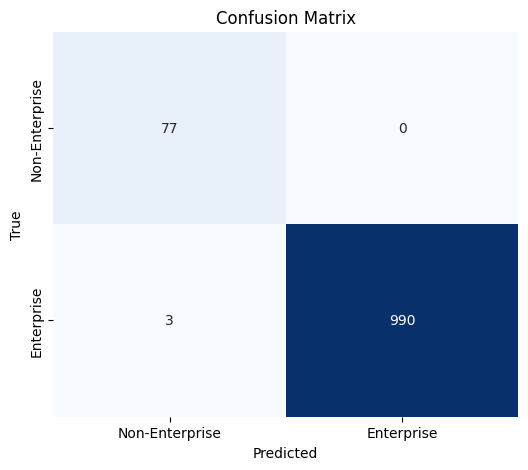

<ipython-input-24-0194b73a5017>:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette='coolwarm')


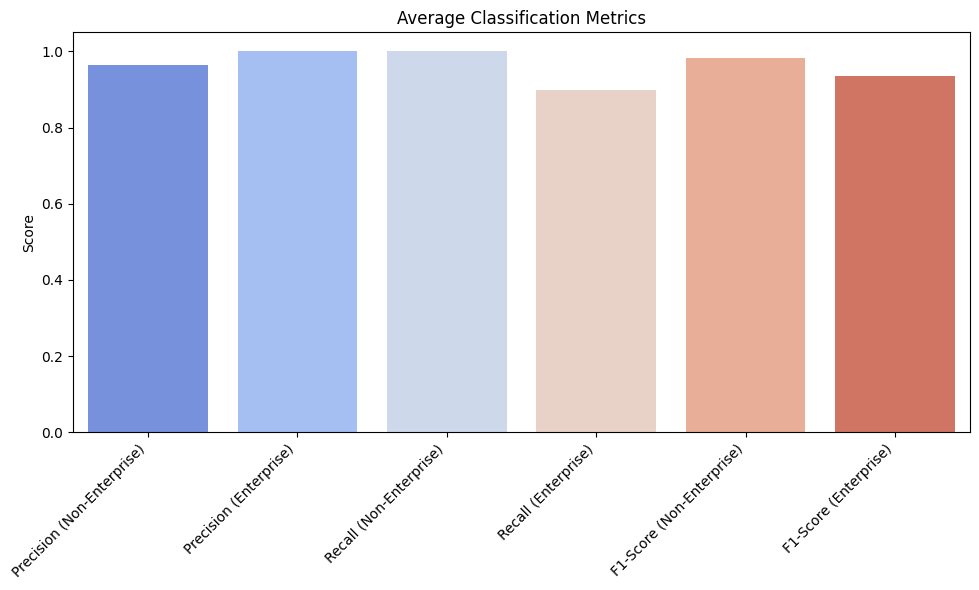

       Key  Overall Accuracy  Precision (Non-Enterprise)  \
0  dyncorp          0.928571                    0.923077   
1   mormon          1.000000                    1.000000   
2       tm          1.000000                    1.000000   
3      pii          1.000000                    1.000000   
4   google          0.950000                    0.909091   
5    enron          0.998969                    0.952381   

   Precision (Enterprise)  Recall (Non-Enterprise)  Recall (Enterprise)  \
0                     1.0                      1.0             0.500000   
1                     1.0                      1.0             1.000000   
2                     1.0                      1.0             1.000000   
3                     1.0                      1.0             1.000000   
4                     1.0                      1.0             0.900000   
5                     1.0                      1.0             0.998947   

   F1-Score (Non-Enterprise)  F1-Score (Enterprise)  

In [ ]:
def generate_classification_report(data, classifier_1, classifier_2, vectorizer):
    clf_pipeline = TwoStepClassifier(classifier_1, classifier_2, vectorizer)

    # Prepare a DataFrame to store results for each key
    results = []
    all_predictions = []
    all_true_labels = []

    # Iterate through each key in the dataset
    for key, df in data.items():
        X = df['content']
        y = df['label']

        # Predict all rows at once using the clf_pipeline
        predictions = clf_pipeline.predict(X)
        all_predictions.extend(predictions)
        all_true_labels.extend(y)

        # Calculate classification metrics
        classification_metrics = classification_report(y, predictions, output_dict=True, zero_division=1)
        confusion = confusion_matrix(y, predictions)

        # Prepare the results for each dataset
        result = {
            'Key': key,
            'Overall Accuracy': accuracy_score(y, predictions),
            'Precision (Non-Enterprise)': classification_metrics['0']['precision'],
            'Precision (Enterprise)': classification_metrics['1']['precision'],
            'Recall (Non-Enterprise)': classification_metrics['0']['recall'],
            'Recall (Enterprise)': classification_metrics['1']['recall'],
            'F1-Score (Non-Enterprise)': classification_metrics['0']['f1-score'],
            'F1-Score (Enterprise)': classification_metrics['1']['f1-score'],
            'Confusion Matrix': confusion.tolist(),
        }
        results.append(result)

    # Create DataFrame to display all the results
    results_df = pd.DataFrame(results)

    # Plot confusion matrix for the entire dataset
    cm = confusion_matrix(all_true_labels, all_predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Sensitive', 'Sensitive'],
                yticklabels=['Non-Sensitive', 'Sensitive'], cbar=False)
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    # Plot Precision, Recall, and F1-Score for both classes
    metrics = ['Precision (Non-Enterprise)', 'Precision (Enterprise)',
               'Recall (Non-Enterprise)', 'Recall (Enterprise)',
               'F1-Score (Non-Enterprise)', 'F1-Score (Enterprise)']
    values = [
        results_df['Precision (Non-Enterprise)'].mean(),
        results_df['Precision (Enterprise)'].mean(),
        results_df['Recall (Non-Enterprise)'].mean(),
        results_df['Recall (Enterprise)'].mean(),
        results_df['F1-Score (Non-Enterprise)'].mean(),
        results_df['F1-Score (Enterprise)'].mean(),
    ]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=metrics, y=values, palette='coolwarm')
    plt.title('Average Classification Metrics')
    plt.ylabel('Score')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return results_df

# Example usage: Generate and print the classification report for all keys
classification_results = generate_classification_report(test_data, model_1, model_2, tf_idf)
print(classification_results)

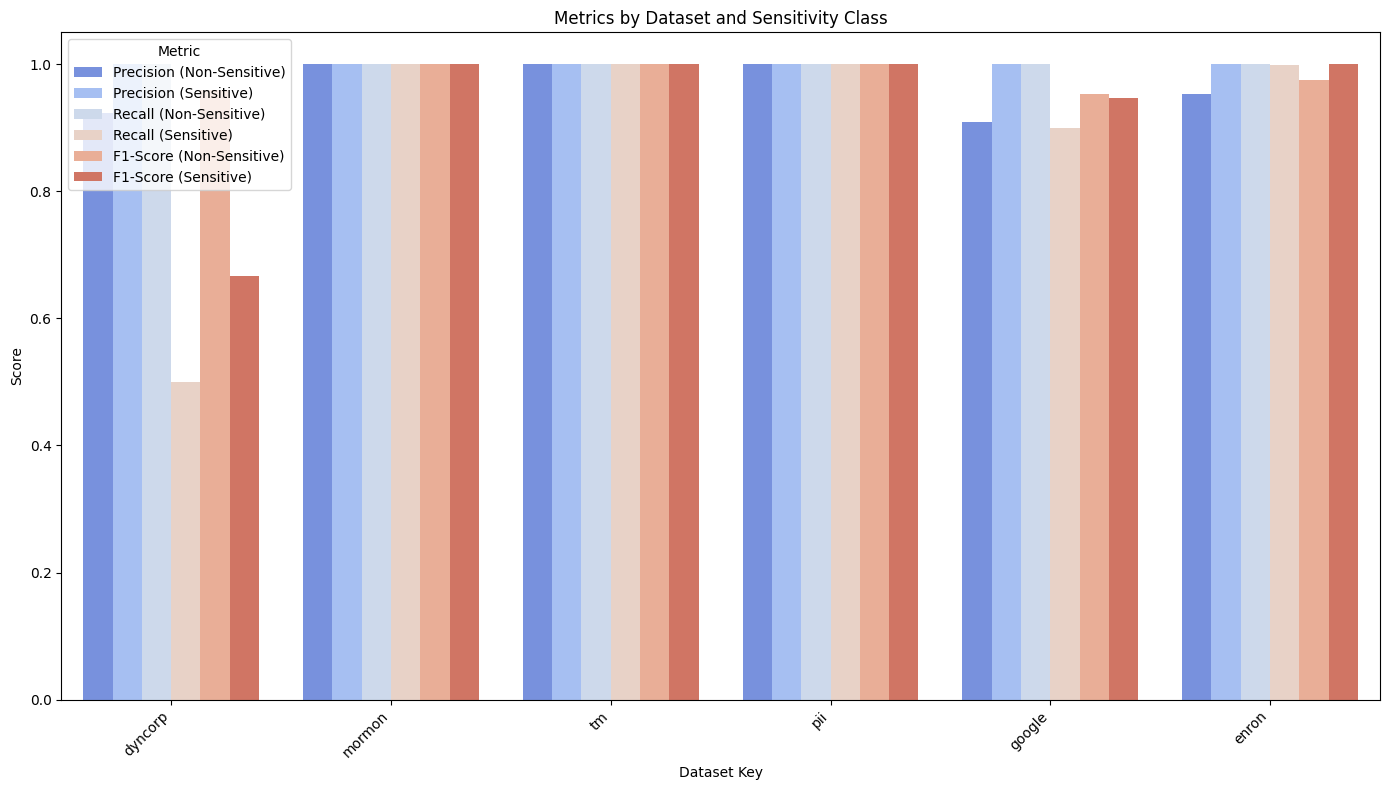

       Key  Overall Accuracy  Precision (Non-Sensitive)  \
0  dyncorp          0.928571                   0.923077   
1   mormon          1.000000                   1.000000   
2       tm          1.000000                   1.000000   
3      pii          1.000000                   1.000000   
4   google          0.950000                   0.909091   
5    enron          0.998969                   0.952381   

   Precision (Sensitive)  Recall (Non-Sensitive)  Recall (Sensitive)  \
0                    1.0                     1.0            0.500000   
1                    1.0                     1.0            1.000000   
2                    1.0                     1.0            1.000000   
3                    1.0                     1.0            1.000000   
4                    1.0                     1.0            0.900000   
5                    1.0                     1.0            0.998947   

   F1-Score (Non-Sensitive)  F1-Score (Sensitive)     Confusion Matrix  
0       

In [ ]:
def generate_classification_report(data, classifier_1, classifier_2, vectorizer):
    clf_pipeline = TwoStepClassifier(classifier_1, classifier_2, vectorizer)

    # Prepare a DataFrame to store results for each key
    results = []
    all_predictions = []
    all_true_labels = []

    # Iterate through each key in the dataset
    for key, df in data.items():
        X = df['content']
        y = df['label']

        # Predict all rows at once using the clf_pipeline
        predictions = clf_pipeline.predict(X)
        all_predictions.extend(predictions)
        all_true_labels.extend(y)

        # Calculate classification metrics
        classification_metrics = classification_report(y, predictions, output_dict=True, zero_division=1)
        confusion = confusion_matrix(y, predictions)

        # Prepare the results for each dataset
        result = {
            'Key': key,
            'Overall Accuracy': accuracy_score(y, predictions),
            'Precision (Non-Sensitive)': classification_metrics['0']['precision'],
            'Precision (Sensitive)': classification_metrics['1']['precision'],
            'Recall (Non-Sensitive)': classification_metrics['0']['recall'],
            'Recall (Sensitive)': classification_metrics['1']['recall'],
            'F1-Score (Non-Sensitive)': classification_metrics['0']['f1-score'],
            'F1-Score (Sensitive)': classification_metrics['1']['f1-score'],
            'Confusion Matrix': confusion.tolist(),
        }
        results.append(result)

    # Create DataFrame to display all the results
    results_df = pd.DataFrame(results)

    # Plot Precision, Recall, and F1-Score for both classes, grouped by dataset key
    metrics = ['Precision', 'Recall', 'F1-Score']
    categories = ['Non-Sensitive', 'Sensitive']

    # Prepare data for plotting
    plot_data = []
    for _, row in results_df.iterrows():
        key = row['Key']
        for metric in metrics:
            for category in categories:
                plot_data.append({
                    'Key': key,
                    'Metric': f'{metric} ({category})',
                    'Score': row[f'{metric} ({category})']
                })

    plot_df = pd.DataFrame(plot_data)

    # Create a grouped bar plot for each dataset with different metrics (Precision, Recall, F1-Score)
    plt.figure(figsize=(14, 8))
    sns.barplot(x='Key', y='Score', hue='Metric', data=plot_df, palette='coolwarm')
    plt.title('Metrics by Dataset and Sensitivity Class')
    plt.ylabel('Score')
    plt.xlabel('Dataset Key')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.legend(title='Metric')
    plt.show()

    return results_df

# Example usage: Generate and print the classification report for all keys
classification_results = generate_classification_report(test_data, model_1, model_2, tf_idf)
print(classification_results)

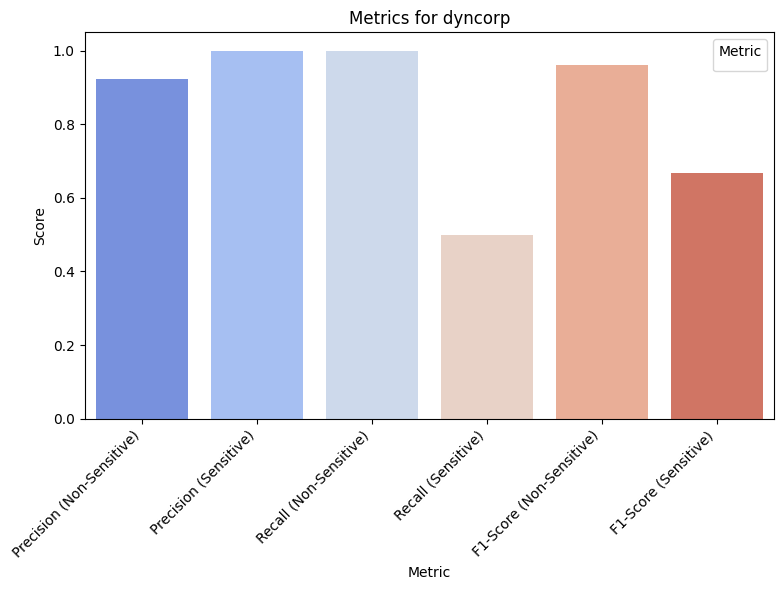

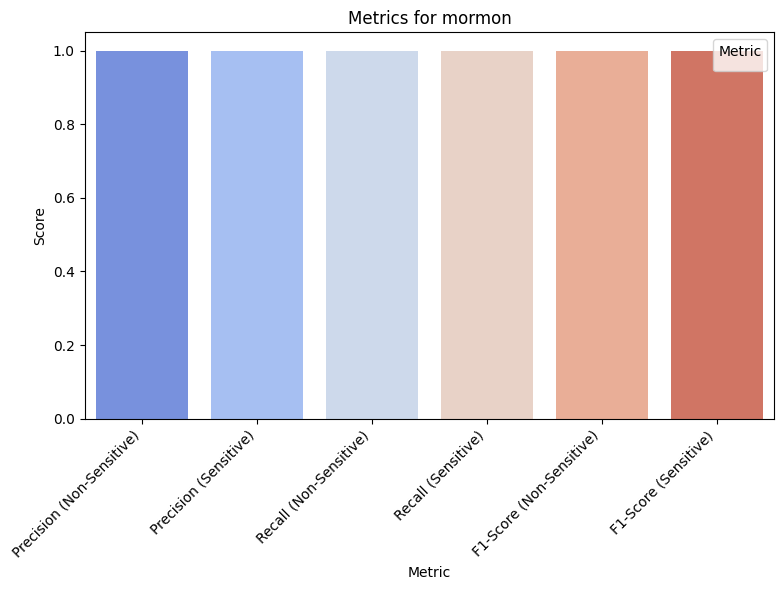

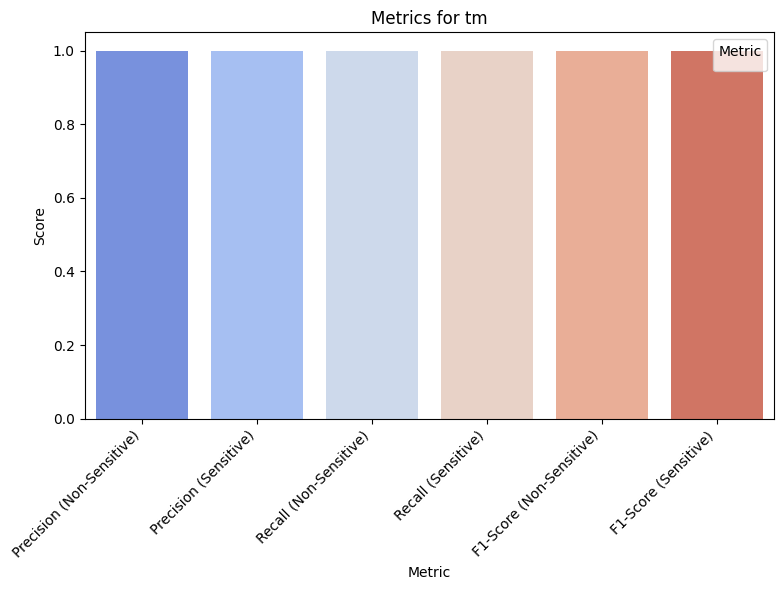

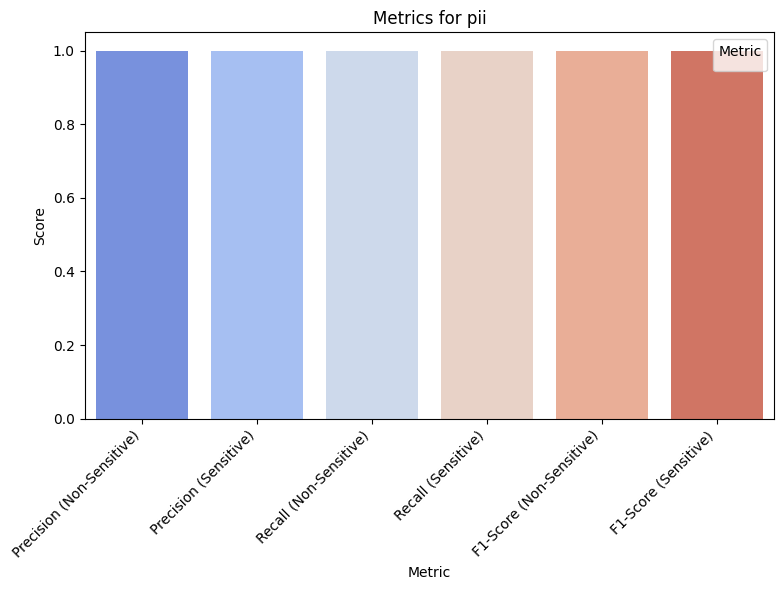

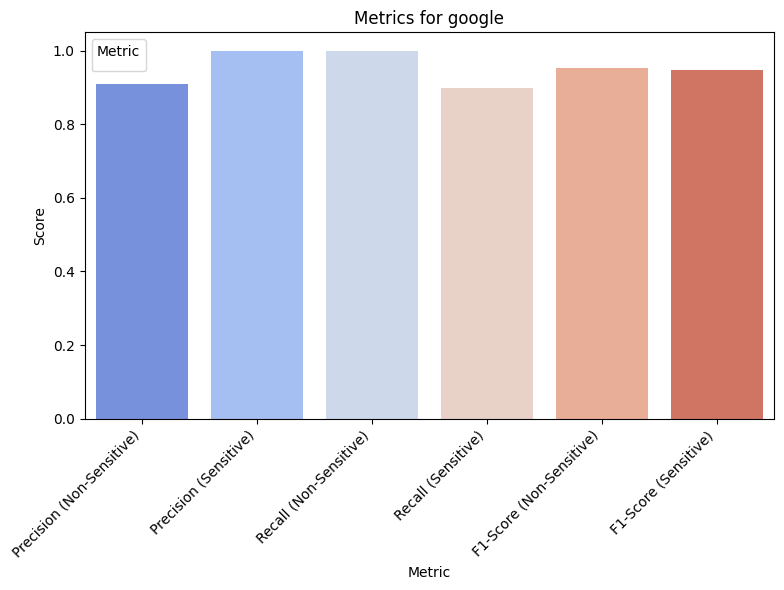

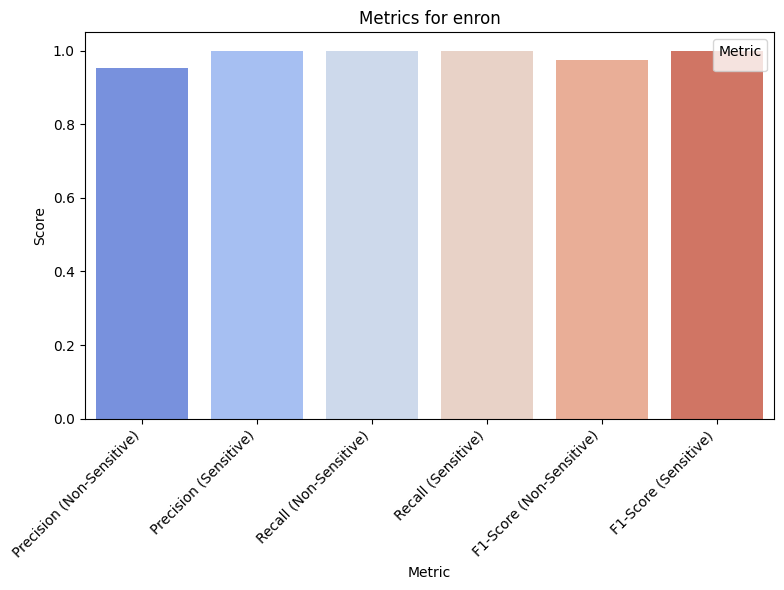

In [ ]:
def plot_separate_graphs(results_df):
    metrics = ['Precision', 'Recall', 'F1-Score']
    categories = ['Non-Sensitive', 'Sensitive']

    # Prepare data for plotting
    plot_data = []
    for _, row in results_df.iterrows():
        key = row['Key']
        for metric in metrics:
            for category in categories:
                plot_data.append({
                    'Key': key,
                    'Metric': f'{metric} ({category})',
                    'Score': row[f'{metric} ({category})']
                })

    plot_df = pd.DataFrame(plot_data)

    # Create a separate plot for each dataset key
    unique_keys = plot_df['Key'].unique()

    for key in unique_keys:
        plt.figure(figsize=(8, 6))
        key_data = plot_df[plot_df['Key'] == key]

        sns.barplot(x='Metric', y='Score', hue='Metric', data=key_data, palette='coolwarm')
        plt.title(f'Metrics for {key}')
        plt.ylabel('Score')
        plt.xlabel('Metric')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.legend(title='Metric')
        plt.show()

# Example usage:
plot_separate_graphs(classification_results)

##LSTM Model

### Tokenizer

In [ ]:
all_data = pd.concat([
    enterprise_private['content'],
    enterprise_public['content'],
    non_enterprise['content']
], ignore_index=True)

In [ ]:
MAX_NB_WORDS = 20000

tokenizer = Tokenizer(num_words=MAX_NB_WORDS)
tokenizer.fit_on_texts(all_data)

####Saving Tokenizer

In [ ]:
tokenizer_filename = './drive/MyDrive/ADS Project/models/Tokenizer.pkl'
joblib.dump(tokenizer, tokenizer_filename)

['./drive/MyDrive/ADS Project/models/Tokenizer.pkl']

####Loading Tokenizer

In [ ]:
tokenizer_filename = './drive/MyDrive/ADS Project/models/Tokenizer.pkl'
tokenizer = joblib.load(tokenizer_filename)

### First Classifier

In [ ]:
enterprise_private['label'] = 1
enterprise_public['label'] = 1

non_enterprise['label'] = 0

first_classifier_data = pd.concat([enterprise_private, enterprise_public, non_enterprise], axis=0, ignore_index=True)

In [ ]:
X_1 = first_classifier_data["content"]
y_1 = first_classifier_data["label"]

In [ ]:
X_1_train, X_1_test, y_1_train, y_1_test = train_test_split(X_1, y_1, test_size=0.2, stratify=y_1, random_state=42)


In [ ]:
MAX_NB_WORDS = 20000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 100

X_train_seq = tokenizer.texts_to_sequences(X_1_train)
X_test_seq = tokenizer.texts_to_sequences(X_1_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH)
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_SEQUENCE_LENGTH)

In [ ]:
model = Sequential([
    Embedding(input_dim=MAX_NB_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3, kernel_regularizer=l2(0.02))),
    Dense(1, activation='sigmoid', kernel_regularizer=l2(0.02)),
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d_2                  │ ?                           │     0 (unbuilt) │
│ (SpatialDropout1D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_2 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(X_train_pad, y_1_train, epochs=20, batch_size=16, validation_data=(X_test_pad, y_1_test), callbacks=[early_stopping])
y_pred = (model.predict(X_test_pad) > 0.5).astype(int)

Epoch 1/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 380s 356ms/step - accuracy: 0.8408 - loss: 1.2635 - val_accuracy: 0.9435 - val_loss: 0.2347
Epoch 2/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 392s 366ms/step - accuracy: 0.9195 - loss: 0.2987 - val_accuracy: 0.9309 - val_loss: 0.2827
Epoch 3/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 418s 343ms/step - accuracy: 0.9373 - loss: 0.2652 - val_accuracy: 0.9343 - val_loss: 0.2502
Epoch 4/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 381s 342ms/step - accuracy: 0.9434 - loss: 0.2324 - val_accuracy: 0.9713 - val_loss: 0.1804
Epoch 5/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 379s 340ms/step - accuracy: 0.9671 - loss: 0.1858 - val_accuracy: 0.9642 - val_loss: 0.1546
Epoch 6/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 387s 345ms/step - accuracy: 0.9693 - loss: 0.1544 - val_accuracy: 0.9718 - val_loss: 0.1563
Epoch 7/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 357s 338ms/step - accuracy: 0.9690 - loss: 0.1430 - val_accuracy: 0.9784 - val_loss: 0.2087
Epoch 8/20
1054/1054 ━━━━━━━━━━━━━━━━━━━━ 388s 344ms/step - ac

Accuracy: 0.9641585568478519
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.95      0.97      2288
           1       0.94      0.98      0.96      1925

    accuracy                           0.96      4213
   macro avg       0.96      0.97      0.96      4213
weighted avg       0.97      0.96      0.96      4213



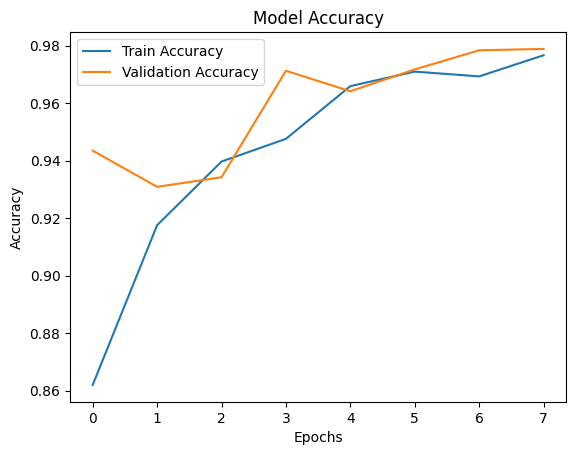

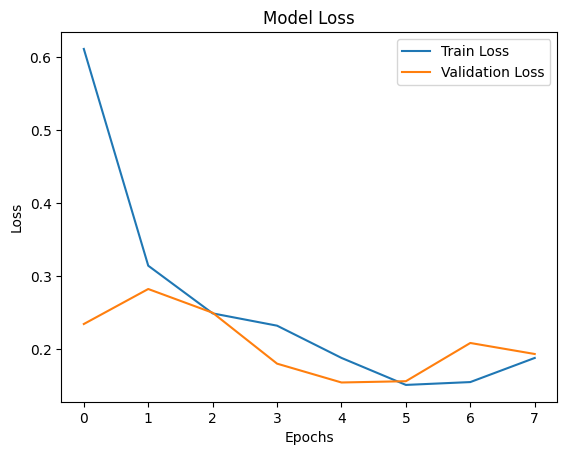

In [ ]:
print(f"Accuracy: {accuracy_score(y_1_test, y_pred)}")
print("Classification Report:")
print(classification_report(y_1_test, y_pred))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

####Saving Model 1

In [ ]:
model_1_filename = './drive/MyDrive/ADS Project/models/LSTM_model_1.pkl'
joblib.dump(model, model_1_filename)

['./drive/MyDrive/ADS Project/models/LSTM_model_1.pkl']

####Loading Model 1


In [ ]:
model_1_filename = './drive/MyDrive/ADS Project/models/LSTM_model_1.pkl'
model_1 = joblib.load(model_1_filename)

###Second Classifier

In [ ]:
enterprise_private['label'] = 1
enterprise_public['label'] = 0


second_classifier_data = pd.concat([enterprise_private, enterprise_public], axis=0, ignore_index=True)

In [ ]:
X_2 = second_classifier_data["content"]
y_2 = second_classifier_data["label"]

In [ ]:
X_2_train, X_2_test, y_2_train, y_2_test = train_test_split(X_2, y_2, test_size=0.2, stratify=y_2, random_state=42)


In [ ]:
MAX_NB_WORDS = 20000
MAX_SEQUENCE_LENGTH = 100
EMBEDDING_DIM = 100

X_train_seq = tokenizer.texts_to_sequences(X_2_train)
X_test_seq = tokenizer.texts_to_sequences(X_2_test)


X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_SEQUENCE_LENGTH)
X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_SEQUENCE_LENGTH)


In [ ]:
model = Sequential([
    Embedding(input_dim=MAX_NB_WORDS, output_dim=EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH),
    SpatialDropout1D(0.3),
    Bidirectional(LSTM(64, dropout=0.3, recurrent_dropout=0.3, kernel_regularizer=l2(0.02))),
    Dense(1, activation='sigmoid', kernel_regularizer=l2(0.02)),
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ spatial_dropout1d_3                  │ ?                           │     0 (unbuilt) │
│ (SpatialDropout1D)                   │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_3 (Bidirectional)      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
history = model.fit(X_train_pad, y_2_train, epochs=20, batch_size=16, validation_data=(X_test_pad, y_2_test), callbacks=[early_stopping])
y_pred = (model.predict(X_test_pad) > 0.5).astype(int)

Epoch 1/20
482/482 ━━━━━━━━━━━━━━━━━━━━ 166s 338ms/step - accuracy: 0.9206 - loss: 1.7588 - val_accuracy: 0.9611 - val_loss: 0.1637
Epoch 2/20
482/482 ━━━━━━━━━━━━━━━━━━━━ 202s 339ms/step - accuracy: 0.9303 - loss: 0.1906 - val_accuracy: 0.9626 - val_loss: 0.1546
Epoch 3/20
482/482 ━━━━━━━━━━━━━━━━━━━━ 163s 339ms/step - accuracy: 0.9383 - loss: 0.1731 - val_accuracy: 0.9294 - val_loss: 0.2595
Epoch 4/20
482/482 ━━━━━━━━━━━━━━━━━━━━ 202s 340ms/step - accuracy: 0.9224 - loss: 0.2740 - val_accuracy: 0.9294 - val_loss: 0.2555
Epoch 5/20
482/482 ━━━━━━━━━━━━━━━━━━━━ 202s 340ms/step - accuracy: 0.9294 - loss: 0.2401 - val_accuracy: 0.9294 - val_loss: 0.2567
61/61 ━━━━━━━━━━━━━━━━━━━━ 7s 103ms/step


Accuracy: 0.9626168224299065
Classification Report:
              precision    recall  f1-score   support

           0       0.73      0.74      0.74       136
           1       0.98      0.98      0.98      1790

    accuracy                           0.96      1926
   macro avg       0.86      0.86      0.86      1926
weighted avg       0.96      0.96      0.96      1926



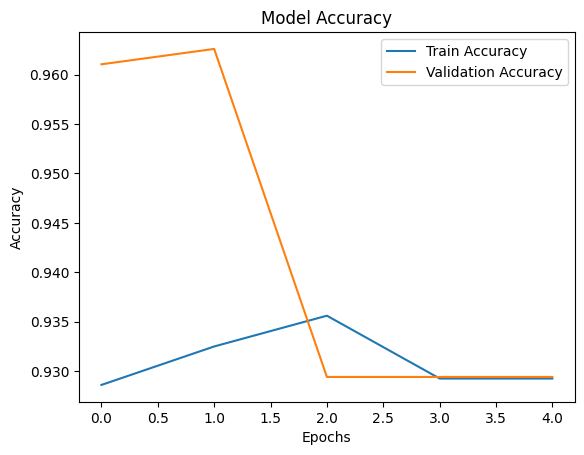

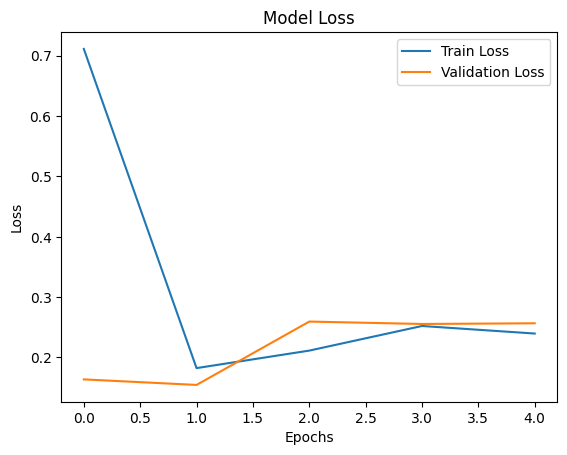

In [ ]:
print(f"Accuracy: {accuracy_score(y_2_test, y_pred)}")
print("Classification Report:")
print(classification_report(y_2_test, y_pred))

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

####Saving Model 2

In [ ]:
model_2_filename = './drive/MyDrive/ADS Project/models/LSTM_model_2.pkl'
joblib.dump(model, model_2_filename)

['./drive/MyDrive/ADS Project/models/LSTM_model_2.pkl']

####Loading Model 2

In [ ]:
model_2_filename = './drive/MyDrive/ADS Project/models/LSTM_model_2.pkl'
model_2 = joblib.load(model_2_filename)

###Pipeline

In [ ]:
class TwoStepClassifier:
    def __init__(self, classifier_1, classifier_2):
        self.classifier_1 = classifier_1
        self.classifier_2 = classifier_2

    def replace_sensitive_info(self, text):
        text = re.sub(r'\+977[-.\s]?\d{10}', 'PHONE_NUM', text)
        text = re.sub(r'\b(?:\d{4}[-.\s]?)\d{4}[-.\s]?\d{4}[-.\s]?\d{4}\b', 'CREDIT_CARD', text)
        text = re.sub(r'\b\d{9,20}\b', 'ACCOUNT_NUM', text)
        text = re.sub(r'\b\d{2}/\d{2}\b', 'EXPIRY_DATE', text)
        text = re.sub(r'\b\d{3}\b', 'CVC_CODE', text)
        return text

    def preprocess_text(self, text):
        stop_words = set(stopwords.words('english'))
        stemmer = PorterStemmer()
        text = self.replace_sensitive_info(text)
        text = text.lower()
        text = re.sub(r'[^a-zA-Z\sPHONE_NUMCREDIT_CARDACCOUNT_NUMEXPIRY_DATECVC_CODE]', '', text)
        words = word_tokenize(text)
        words = [stemmer.stem(word) for word in words if word not in stop_words]
        return ' '.join(words)

    def predict(self, X):
        X_processed = [self.preprocess_text(text) for text in X]

        X_tokenized = tokenizer.texts_to_sequences(X_processed)

        X_padded = pad_sequences(X_tokenized, maxlen=MAX_SEQUENCE_LENGTH)

        step_1_preds = self.classifier_1.predict(X_padded)

        final_preds = np.zeros_like(step_1_preds)

        enterprise_indices = np.where(step_1_preds == 1)[0]

        if len(enterprise_indices) > 0:
            enterprise_features = X_padded[enterprise_indices]
            step_2_preds = self.classifier_2.predict(enterprise_features)
            final_preds[enterprise_indices] = step_2_preds  # Sensitive = 1, Non-Sensitive = 0

        return final_preds

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 81ms/step


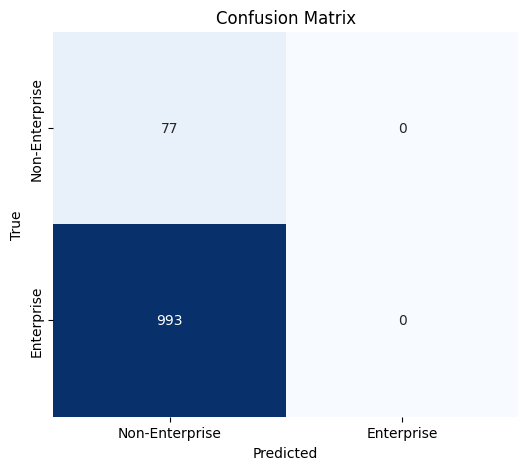

<ipython-input-61-13303f4d68b6>:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metrics, y=values, palette='coolwarm')


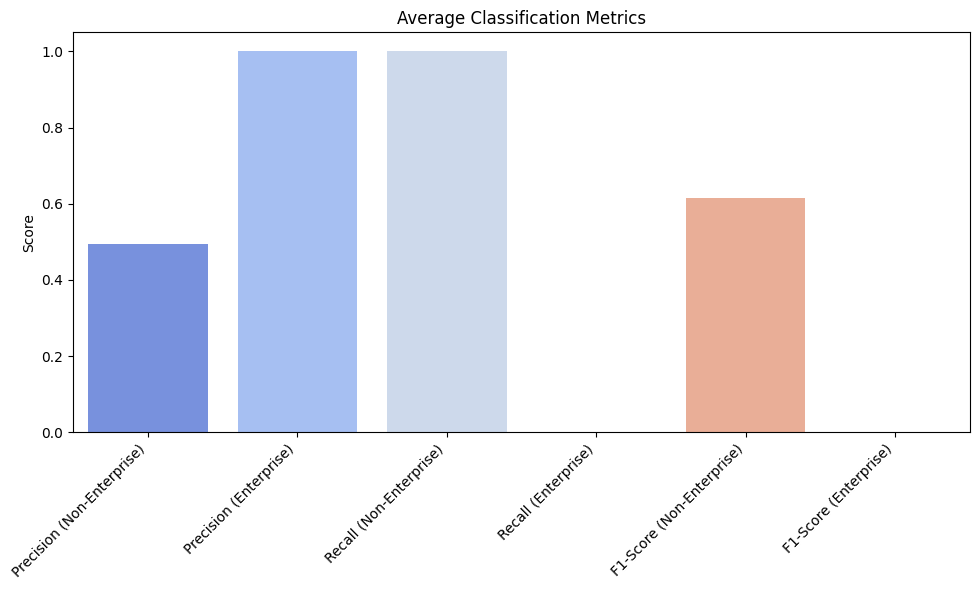

       Key  Overall Accuracy  Precision (Non-Enterprise)  \
0  dyncorp          0.857143                    0.857143   
1   mormon          0.625000                    0.625000   
2       tm          0.444444                    0.444444   
3      pii          0.512195                    0.512195   
4   google          0.500000                    0.500000   
5    enron          0.020619                    0.020619   

   Precision (Enterprise)  Recall (Non-Enterprise)  Recall (Enterprise)  \
0                     1.0                      1.0                  0.0   
1                     1.0                      1.0                  0.0   
2                     1.0                      1.0                  0.0   
3                     1.0                      1.0                  0.0   
4                     1.0                      1.0                  0.0   
5                     1.0                      1.0                  0.0   

   F1-Score (Non-Enterprise)  F1-Score (Enterprise)  

In [ ]:
def generate_classification_report(data, classifier_1, classifier_2):
    clf_pipeline = TwoStepClassifier(classifier_1, classifier_2)

    results = []
    all_predictions = []
    all_true_labels = []

    for key, df in data.items():
        X = df['content']
        y = df['label']

        predictions = clf_pipeline.predict(X)
        all_predictions.extend(predictions)
        all_true_labels.extend(y)

        classification_metrics = classification_report(y, predictions, output_dict=True, zero_division=1)
        confusion = confusion_matrix(y, predictions)

        result = {
            'Key': key,
            'Overall Accuracy': accuracy_score(y, predictions),
            'Precision (Non-Enterprise)': classification_metrics['0']['precision'],
            'Precision (Enterprise)': classification_metrics['1']['precision'],
            'Recall (Non-Enterprise)': classification_metrics['0']['recall'],
            'Recall (Enterprise)': classification_metrics['1']['recall'],
            'F1-Score (Non-Enterprise)': classification_metrics['0']['f1-score'],
            'F1-Score (Enterprise)': classification_metrics['1']['f1-score'],
            'Confusion Matrix': confusion.tolist(),
        }
        results.append(result)

    results_df = pd.DataFrame(results)

    cm = confusion_matrix(all_true_labels, all_predictions)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Enterprise', 'Enterprise'],
                yticklabels=['Non-Enterprise', 'Enterprise'], cbar=False)
    plt.title('Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.show()

    metrics = ['Precision (Non-Enterprise)', 'Precision (Enterprise)',
               'Recall (Non-Enterprise)', 'Recall (Enterprise)',
               'F1-Score (Non-Enterprise)', 'F1-Score (Enterprise)']
    values = [
        results_df['Precision (Non-Enterprise)'].mean(),
        results_df['Precision (Enterprise)'].mean(),
        results_df['Recall (Non-Enterprise)'].mean(),
        results_df['Recall (Enterprise)'].mean(),
        results_df['F1-Score (Non-Enterprise)'].mean(),
        results_df['F1-Score (Enterprise)'].mean(),
    ]

    plt.figure(figsize=(10, 6))
    sns.barplot(x=metrics, y=values, palette='coolwarm')
    plt.title('Average Classification Metrics')
    plt.ylabel('Score')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    return results_df

classification_results = generate_classification_report(test_data, model_1, model_2)
print(classification_results)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
31/31 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step


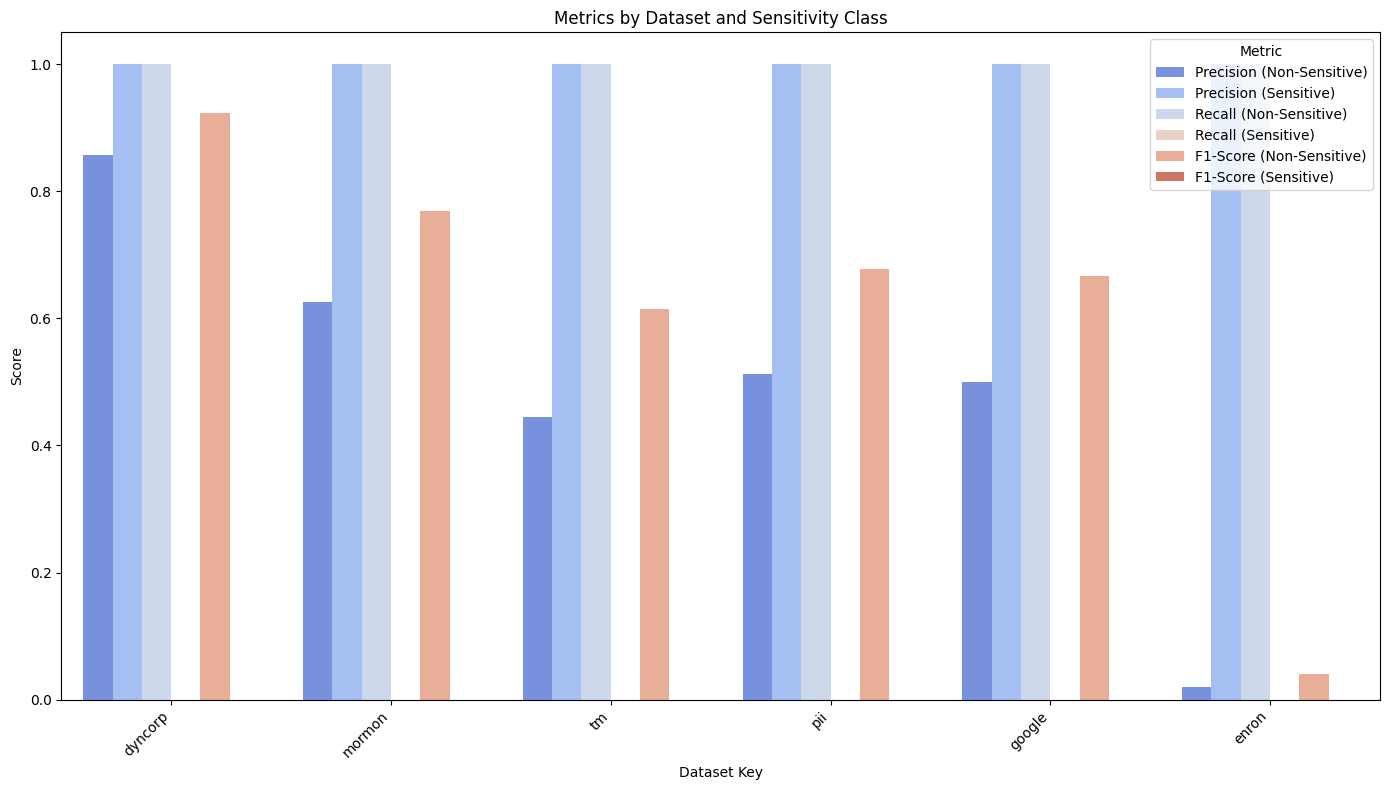

       Key  Overall Accuracy  Precision (Non-Sensitive)  \
0  dyncorp          0.857143                   0.857143   
1   mormon          0.625000                   0.625000   
2       tm          0.444444                   0.444444   
3      pii          0.512195                   0.512195   
4   google          0.500000                   0.500000   
5    enron          0.020619                   0.020619   

   Precision (Sensitive)  Recall (Non-Sensitive)  Recall (Sensitive)  \
0                    1.0                     1.0                 0.0   
1                    1.0                     1.0                 0.0   
2                    1.0                     1.0                 0.0   
3                    1.0                     1.0                 0.0   
4                    1.0                     1.0                 0.0   
5                    1.0                     1.0                 0.0   

   F1-Score (Non-Sensitive)  F1-Score (Sensitive)     Confusion Matrix  
0       

In [ ]:
def generate_classification_report(data, classifier_1, classifier_2):
    clf_pipeline = TwoStepClassifier(classifier_1, classifier_2)

    results = []
    all_predictions = []
    all_true_labels = []

    for key, df in data.items():
        X = df['content']
        y = df['label']

        predictions = clf_pipeline.predict(X)
        all_predictions.extend(predictions)
        all_true_labels.extend(y)

        classification_metrics = classification_report(y, predictions, output_dict=True, zero_division=1)
        confusion = confusion_matrix(y, predictions)

        result = {
            'Key': key,
            'Overall Accuracy': accuracy_score(y, predictions),
            'Precision (Non-Sensitive)': classification_metrics['0']['precision'],
            'Precision (Sensitive)': classification_metrics['1']['precision'],
            'Recall (Non-Sensitive)': classification_metrics['0']['recall'],
            'Recall (Sensitive)': classification_metrics['1']['recall'],
            'F1-Score (Non-Sensitive)': classification_metrics['0']['f1-score'],
            'F1-Score (Sensitive)': classification_metrics['1']['f1-score'],
            'Confusion Matrix': confusion.tolist(),
        }
        results.append(result)

    results_df = pd.DataFrame(results)

    metrics = ['Precision', 'Recall', 'F1-Score']
    categories = ['Non-Sensitive', 'Sensitive']

    plot_data = []
    for _, row in results_df.iterrows():
        key = row['Key']
        for metric in metrics:
            for category in categories:
                plot_data.append({
                    'Key': key,
                    'Metric': f'{metric} ({category})',
                    'Score': row[f'{metric} ({category})']
                })

    plot_df = pd.DataFrame(plot_data)

    plt.figure(figsize=(14, 8))
    sns.barplot(x='Key', y='Score', hue='Metric', data=plot_df, palette='coolwarm')
    plt.title('Metrics by Dataset and Sensitivity Class')
    plt.ylabel('Score')
    plt.xlabel('Dataset Key')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.legend(title='Metric')
    plt.show()

    return results_df

classification_results = generate_classification_report(test_data, model_1, model_2)
print(classification_results)

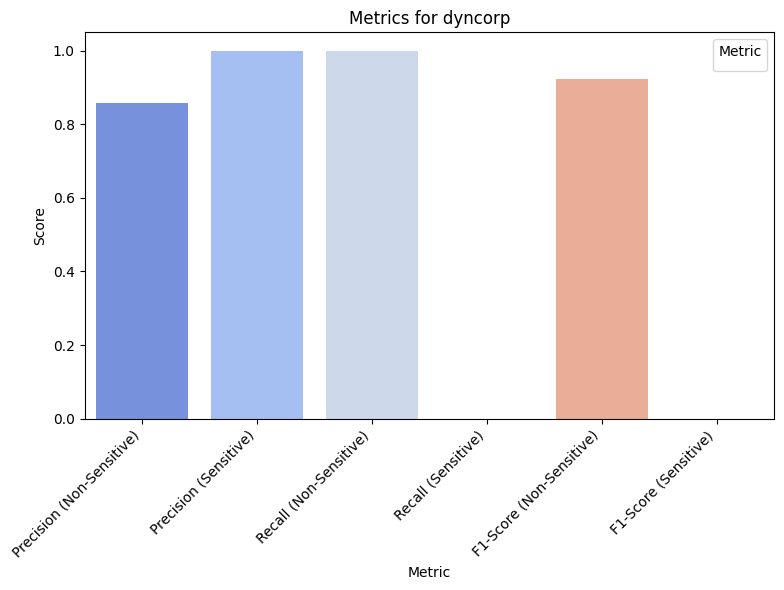

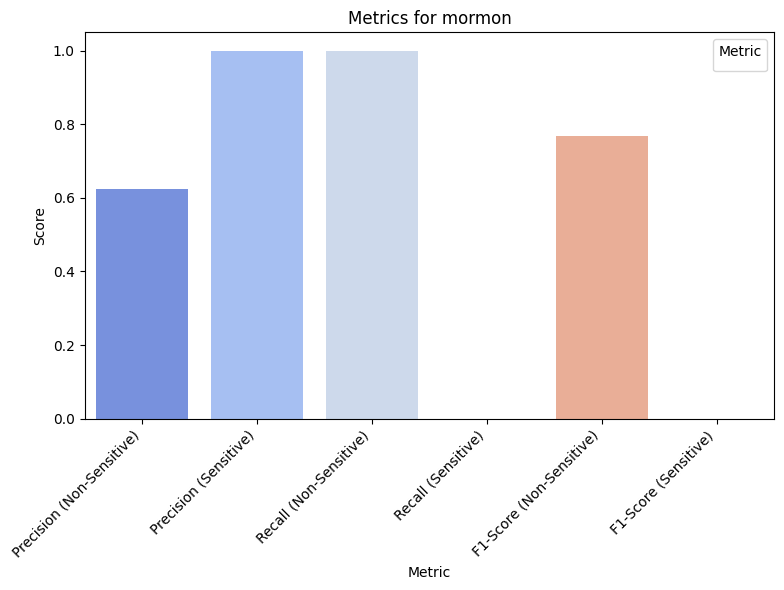

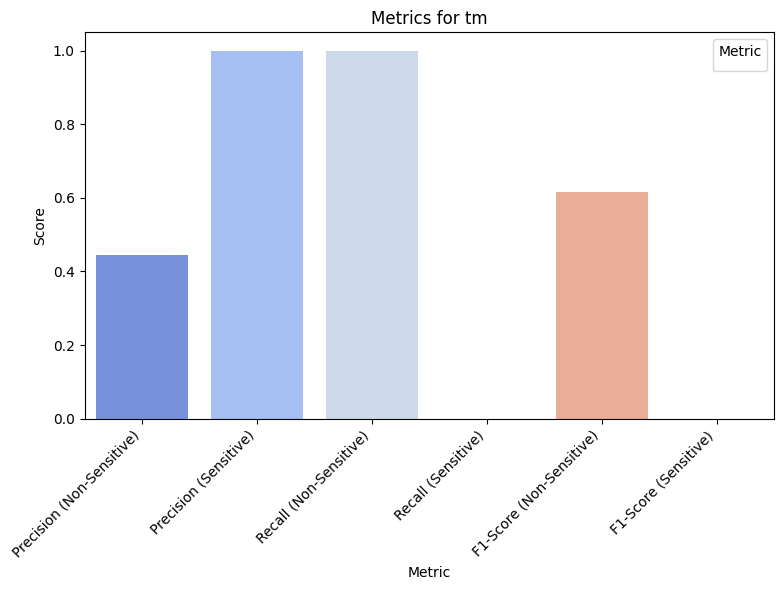

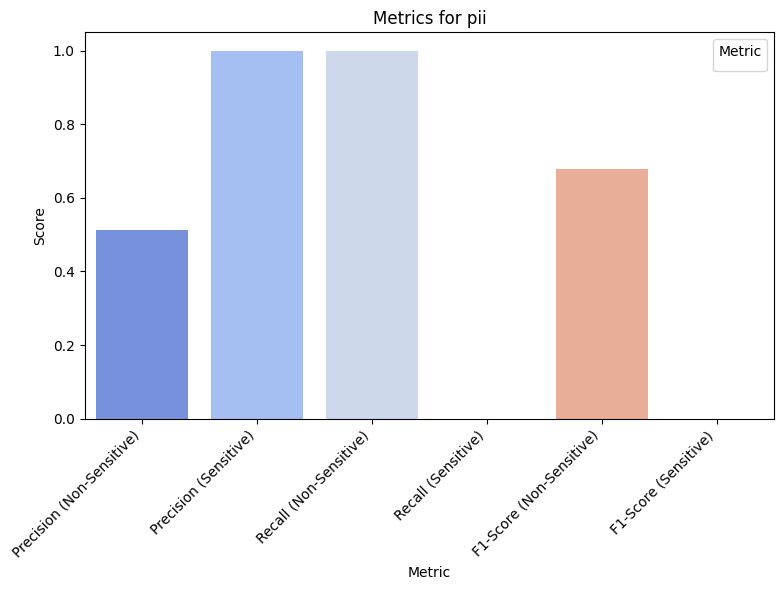

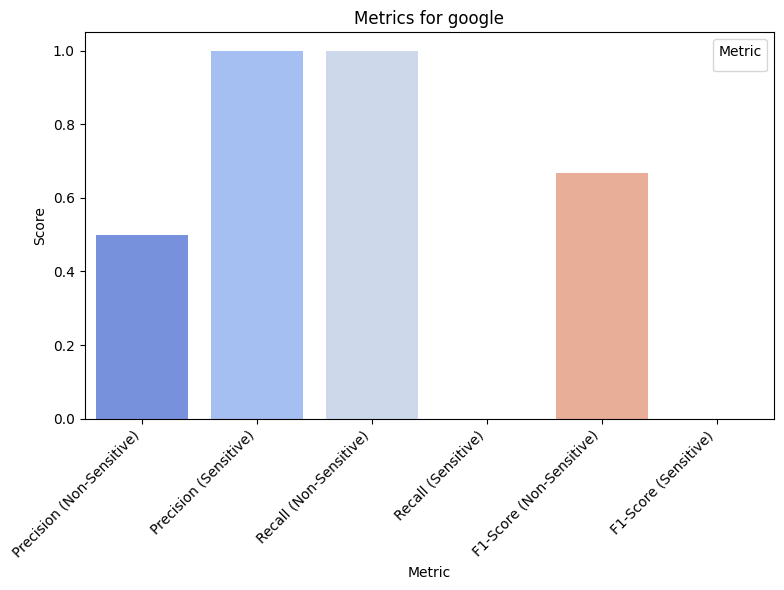

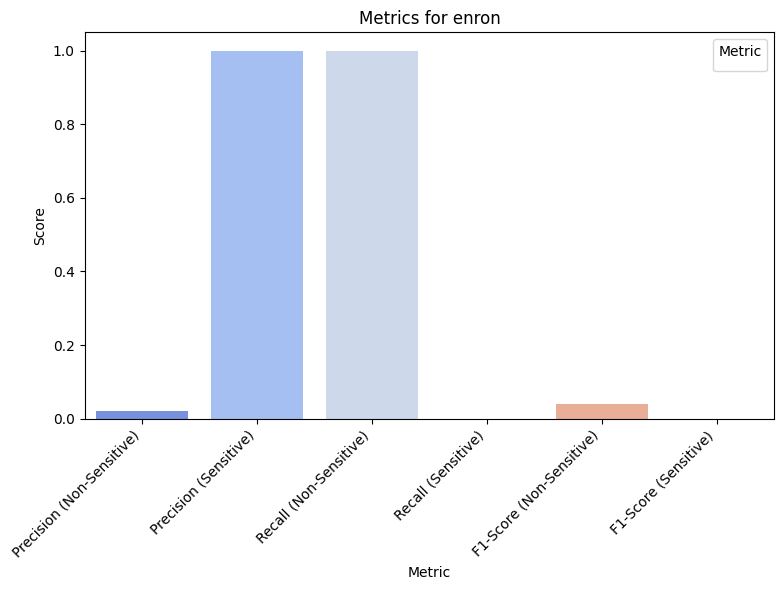

In [ ]:
def plot_separate_graphs(results_df):
    metrics = ['Precision', 'Recall', 'F1-Score']
    categories = ['Non-Sensitive', 'Sensitive']

    plot_data = []
    for _, row in results_df.iterrows():
        key = row['Key']
        for metric in metrics:
            for category in categories:
                plot_data.append({
                    'Key': key,
                    'Metric': f'{metric} ({category})',
                    'Score': row[f'{metric} ({category})']
                })

    plot_df = pd.DataFrame(plot_data)

    unique_keys = plot_df['Key'].unique()

    for key in unique_keys:
        plt.figure(figsize=(8, 6))
        key_data = plot_df[plot_df['Key'] == key]

        sns.barplot(x='Metric', y='Score', hue='Metric', data=key_data, palette='coolwarm')
        plt.title(f'Metrics for {key}')
        plt.ylabel('Score')
        plt.xlabel('Metric')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.legend(title='Metric')
        plt.show()

plot_separate_graphs(classification_results)